In [21]:
import pandas as pd

df = pd.read_csv("./baseline(1).csv")
df.head()

,implementation,documentChars,documentLines,payloadLength,operation,functionName,durationMS,cursorIndex,currentLineChars,selectionLength,timestamp
0,baseline,10,1,10,insert,pushToUndo,0.000000,0,10,0,1792091223051
1,baseline,10,1,10,insert,insertText,0.000000,150,10,0,1792091223051
2,baseline,10,1,10,insert,renderDOM,0.066667,150,160,0,1792091223051
3,baseline,10,1,10,enter,pushToUndo,0.000000,0,10,0,1792091223053
4,baseline,10,1,10,enter,handleEnter,0.000000,0,10,0,1792091223053


In [22]:
import pandas as pd

analysis = pd.read_csv("./baseline(1).csv")
analysis["durationMS"] = pd.to_numeric(analysis["durationMS"])

function_stats = analysis.groupby("functionName")["durationMS"].agg(
    samples="size",
    zero_fraction=lambda values: values.eq(0).mean(),
    median_ms="median",
    p90_ms=lambda values: values.quantile(0.9),
    max_ms="max",
).sort_values("median_ms", ascending=False)

display(function_stats)
display(analysis.groupby(["operation", "functionName"]).size().rename("rows").to_frame())

insert_rows = analysis[analysis["functionName"].eq("insertText")].copy()
insert_rows["estimated_start_cursor"] = insert_rows["cursorIndex"] - 15 * insert_rows["payloadLength"]
display(insert_rows[["documentChars", "payloadLength", "currentLineChars", "cursorIndex", "estimated_start_cursor", "durationMS"]].head(12))

,samples,zero_fraction,median_ms,p90_ms,max_ms
functionName,,,,,
renderDOM,2048,0.146973,0.266667,5.666667,80.666667
handleBackspace,256,0.925781,0.000000,0.000000,0.133333
handleEnter,256,0.941406,0.000000,0.000000,0.133333
handleMovement,256,0.953125,0.000000,0.000000,0.066667
insertText,256,0.890625,0.000000,0.066667,0.200000
handleTab,256,0.941406,0.000000,0.000000,0.133333
pushToUndo,1280,0.867969,0.000000,0.066667,0.733333
redo,256,0.972656,0.000000,0.000000,0.066667
removeSelectedText,256,0.968750,0.000000,0.000000,0.133333


rows
operation functionName            
backspace handleBackspace      256
          pushToUndo           256
          renderDOM            256
cut       pushToUndo           256
          removeSelectedText   256
          renderDOM            256
enter     handleEnter          256
          pushToUndo           256
          renderDOM            256
insert    insertText           256
          pushToUndo           256
          renderDOM            256
move      handleMovement       256
          renderDOM            256
redo      redo                 256
          renderDOM            256
tab       handleTab            256
          pushToUndo           256
          renderDOM            256
undo      renderDOM            256
          undo                 256

,documentChars,payloadLength,currentLineChars,cursorIndex,estimated_start_cursor,durationMS
1,10,10,10,150,0,0.0
22,10,100,10,1500,0,0.0
43,10,1000,10,15000,0,0.0
64,10,10000,10,150000,0,0.0
85,10,10,10,153,3,0.0
106,10,100,10,1503,3,0.0
127,10,1000,10,15003,3,0.0
148,10,10000,10,150003,3,0.0
169,10,10,10,156,6,0.0
190,10,100,10,1506,6,0.0


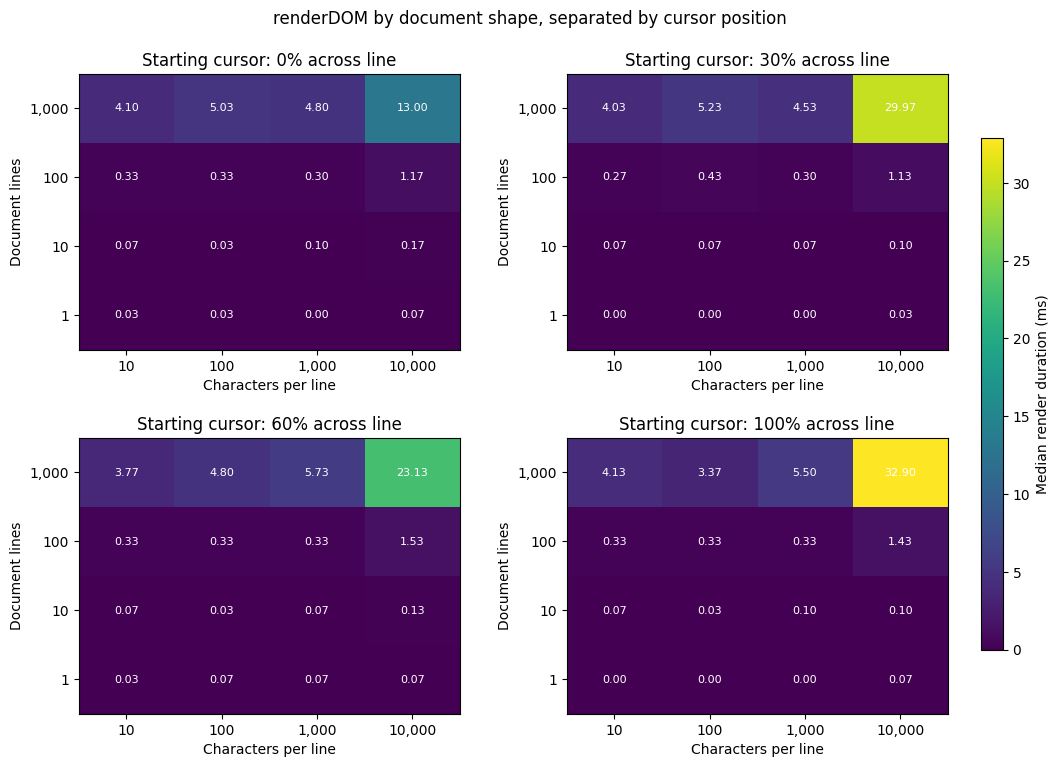

,cursor_fraction,documentLines,currentLineChars,samples,median_ms
0,0.0,1,10,4,0.0333
1,0.0,1,100,4,0.0333
2,0.0,1,1000,4,0.0000
3,0.0,1,10000,4,0.0667
4,0.0,10,10,4,0.0667
...,...,...,...,...,...
59,1.0,100,10000,4,1.4333
60,1.0,1000,10,4,4.1333
61,1.0,1000,100,4,3.3667
62,1.0,1000,1000,4,5.5000


In [23]:
# Empty undo leaves the state unchanged, so this render measures the original document and cursor.
render_rows = analysis[
    analysis["functionName"].eq("renderDOM") & analysis["operation"].eq("undo")
].copy()
render_rows["cursor_fraction"] = (
    render_rows["cursorIndex"] / render_rows["currentLineChars"]
).round(2)
render_summary = (
    render_rows.groupby(
        ["cursor_fraction", "documentLines", "currentLineChars"]
    )["durationMS"]
    .agg(samples="size", median_ms="median")
    .reset_index()
)

line_counts = sorted(render_summary["documentLines"].unique())
line_lengths = sorted(render_summary["currentLineChars"].unique())
cursor_fractions = [0.0, 0.3, 0.6, 1.0]
color_max = render_summary["median_ms"].max()

# Axes: document lines (y) by characters per line (x); each panel fixes cursor fraction.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
fig.subplots_adjust(left=0.09, right=0.88, bottom=0.1, top=0.9, wspace=0.28, hspace=0.32)
for ax, cursor_fraction in zip(axes.flat, cursor_fractions):
    panel = render_summary[render_summary["cursor_fraction"].eq(cursor_fraction)]
    grid = panel.pivot(
        index="documentLines", columns="currentLineChars", values="median_ms"
    ).reindex(index=line_counts, columns=line_lengths)
    image = ax.imshow(
        grid.to_numpy(),
        origin="lower",
        aspect="auto",
        cmap="viridis",
        vmin=0,
        vmax=color_max,
    )
    ax.set_title(f"Starting cursor: {cursor_fraction:.0%} across line")
    ax.set_xticks(range(len(line_lengths)), [f"{value:,}" for value in line_lengths])
    ax.set_yticks(range(len(line_counts)), [f"{value:,}" for value in line_counts])
    ax.set_xlabel("Characters per line")
    ax.set_ylabel("Document lines")
    for row_index in range(len(line_counts)):
        for column_index in range(len(line_lengths)):
            value = grid.iloc[row_index, column_index]
            if pd.notna(value):
                ax.text(column_index, row_index, f"{value:.2f}", ha="center", va="center", color="white", fontsize=8)

colorbar_axis = fig.add_axes([0.91, 0.18, 0.02, 0.64])
fig.colorbar(image, cax=colorbar_axis, label="Median render duration (ms)")
fig.suptitle("renderDOM by document shape, separated by cursor position")
plt.show()

display(render_summary.sort_values(["cursor_fraction", "documentLines", "currentLineChars"]).round(4))

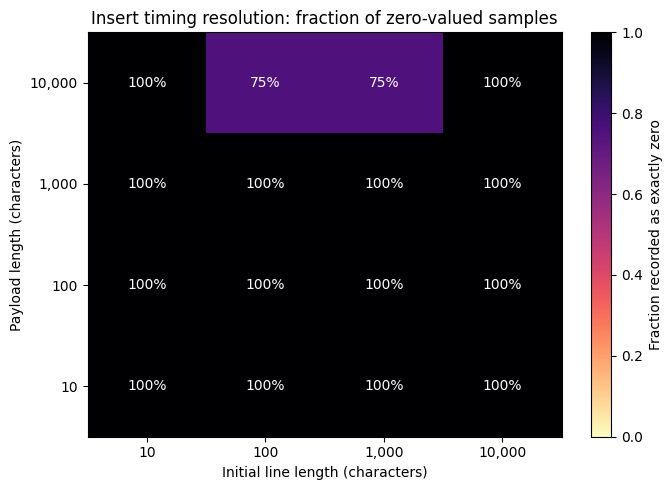

,payloadLength,currentLineChars,samples,zero_fraction,median_ms,max_ms
0,10,10,4,1.00,0.0,0.0000
4,100,10,4,1.00,0.0,0.0000
8,1000,10,4,1.00,0.0,0.0000
12,10000,10,4,1.00,0.0,0.0000
1,10,100,4,1.00,0.0,0.0000
5,100,100,4,1.00,0.0,0.0000
9,1000,100,4,1.00,0.0,0.0000
13,10000,100,4,0.75,0.0,0.0667
2,10,1000,4,1.00,0.0,0.0000
6,100,1000,4,1.00,0.0,0.0000


In [24]:
# This map summarizes timer censoring, not insert speed: each cell pools the four cursor positions.
insert_rows = analysis[
    analysis["functionName"].eq("insertText")
    & analysis["operation"].eq("insert")
    & analysis["documentLines"].eq(1)
].copy()
insert_rows["durationMS"] = pd.to_numeric(insert_rows["durationMS"])
insert_quality = (
    insert_rows.groupby(["payloadLength", "currentLineChars"])["durationMS"]
    .agg(
        samples="size",
        zero_fraction=lambda values: values.eq(0).mean(),
        median_ms="median",
        max_ms="max",
    )
    .reset_index()
)

line_lengths = sorted(insert_quality["currentLineChars"].unique())
payload_lengths = sorted(insert_quality["payloadLength"].unique())
zero_grid = insert_quality.pivot(
    index="payloadLength", columns="currentLineChars", values="zero_fraction"
).reindex(index=payload_lengths, columns=line_lengths)

# Axes: payload length (y) by initial line length (x); color is zero-timing fraction.
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(
    zero_grid.to_numpy(),
    origin="lower",
    aspect="auto",
    cmap="magma_r",
    vmin=0,
    vmax=1,
)
ax.set_xticks(range(len(line_lengths)), [f"{value:,}" for value in line_lengths])
ax.set_yticks(range(len(payload_lengths)), [f"{value:,}" for value in payload_lengths])
ax.set_xlabel("Initial line length (characters)")
ax.set_ylabel("Payload length (characters)")
ax.set_title("Insert timing resolution: fraction of zero-valued samples")
for row_index in range(len(payload_lengths)):
    for column_index in range(len(line_lengths)):
        value = zero_grid.iloc[row_index, column_index]
        ax.text(column_index, row_index, f"{value:.0%}", ha="center", va="center", color="white")
fig.colorbar(image, ax=ax, label="Fraction recorded as exactly zero")
fig.tight_layout()
plt.show()

display(insert_quality.sort_values(["currentLineChars", "payloadLength"]).round(4))

In [25]:
# For a percent-reduction claim, compare identical workloads in paired runs on the same environment.
workload_fields = [
    "suite", "operation", "functionName", "documentLines", "documentChars",
    "cursorLine", "cursorIndex", "currentLineChars", "payloadLength",
    "payloadLines", "selectionLength", "selectionLines", "historyDepth", "repetitions",
]
environment_fields = ["browserName", "browserVersion", "device"]
comparison_fields = [
    "pairId", "implementation", "revision", "durationMS",
    *environment_fields, *workload_fields,
]
missing_fields = sorted(set(comparison_fields) - set(analysis.columns))
display(pd.DataFrame({"comparison field": comparison_fields, "available in legacy CSV": [field not in missing_fields for field in comparison_fields]}))


def compare_paired_runs(results, before="baseline", after="candidate"):
    missing = sorted(set(comparison_fields) - set(results.columns))
    if missing:
        raise ValueError(f"Cannot compare these results; missing fields: {missing}")

    grouping_fields = [
        "pairId", *environment_fields, *workload_fields, "implementation"
    ]
    medians = results.groupby(grouping_fields, dropna=False)["durationMS"].median()
    paired = medians.unstack("implementation")
    if before not in paired or after not in paired:
        raise ValueError(f"Expected implementation labels {before!r} and {after!r}")

    paired = paired[[before, after]].dropna()
    measurable = paired[before] > 0
    excluded_zero_baselines = int((~measurable).sum())
    paired = paired.loc[measurable].copy()
    paired["reduction_pct"] = 100 * (paired[before] - paired[after]) / paired[before]

    summary = paired.groupby(["suite", "operation", "functionName"])["reduction_pct"].agg(
        paired_cases="size",
        median_reduction_pct="median",
        p25_reduction_pct=lambda values: values.quantile(0.25),
        p75_reduction_pct=lambda values: values.quantile(0.75),
    )
    print(f"Matched cases with zero baseline duration excluded: {excluded_zero_baselines}")
    display(summary.round(2))
    return paired

print("Legacy CSV is not ready for a before/after claim; it lacks the paired workload and environment fields above.")

,comparison field,available in legacy CSV
0,pairId,False
1,implementation,True
2,revision,False
3,durationMS,True
4,browserName,False
5,browserVersion,False
6,device,False
7,suite,False
8,operation,True
9,functionName,True


Legacy CSV is not ready for a before/after claim; it lacks the paired workload and environment fields above.


In [26]:
import numpy as np

render_clean = analysis[
    analysis["functionName"].eq("renderDOM") & analysis["operation"].eq("undo")
].copy()
render_clean["cursor_fraction"] = (
    render_clean["cursorIndex"] / render_clean["currentLineChars"]
).round(2)

print("numpy:", np.__version__)
print("clean render rows:", len(render_clean))
print("unique design cells:", render_clean[["documentLines", "currentLineChars", "cursor_fraction"]].drop_duplicates().shape[0])
print("zero duration fraction:", round(render_clean["durationMS"].eq(0).mean(), 3))
display(render_clean.groupby("cursor_fraction")["durationMS"].agg(["count", "median", "mean", "max"]).round(4))

numpy: 2.2.6
clean render rows: 256
unique design cells: 64
zero duration fraction: 0.156


,count,median,mean,max
cursor_fraction,,,,
0.0,64,0.2333,1.8802,15.8000
0.3,64,0.2000,3.0333,42.7333
0.6,64,0.2667,2.7125,45.7333
1.0,64,0.2000,3.0531,56.2667
